# Does subliminal transfer peak early and decay — same-model vs cross-model, Pythia and OLMo

**Question.** Along student training, does same-model transfer rise to an early peak and then
decay, while cross-model transfer (different init, size, architecture or pretraining corpus) does
not? Read on the per-checkpoint `eval/pref_traj.json` of every canonical (teacher × cell) student.

**Conditions.** Pythia-160m (dog / cat / lion / pig, cells = core56, teachers =
`run_logs/registry/{animal}_top10_kband_configs.json`): same-model diagonals `orig/fs1–3`, and
cross-seed = every ordered pair of different inits. Pythia cross-size / cross-architecture (dog,
core30; OLMo receiver core35; teachers from `xarch_significance_arms.json`): 410m ↔ 160m and
OLMo-1B ↔ 160m. OLMo-1B (elephant, core35, teachers from `olmo_cross_seed_significance_arms.json`):
same-model per corpus (dolma, c4, dclm), cross-seed (same corpus, `large-aux-2` init), and
cross-corpus (default-seed pairs, plus the corpus-crossed `aux2`-receiver pairs, labelled
"cross-corpus + cross-seed" and pooled into the OLMo cross-corpus line). Lines are grouped by
RECEIVER family, so no line mixes run lengths: the 160m → OLMo-dolma (dog) cross-architecture arm
is its own dashed line "OLMo cross-arch." (1 arm), and "Pythia cross-size/arch." holds the five
Pythia-receiver arms. Student ftseed 1 only;
teacher seed per registry (tseed1 Pythia, tseed0 OLMo).

**Aggregation rule.** Per arm: *median over alive (teacher × cell) runs of test p_target / receiver
prior, at each saved checkpoint; absolute optimizer steps*. Per condition line: median over the
arms' per-arm medians (every arm equal weight), band = IQR over arms. Alive = not
`train_diverged.json` and under the receiver's anchored ΔCE dead cut at the run endpoint
(`transfer_significance_io._dead_label`); dead, diverged and unlabelled runs are excluded from
every curve and counted in the inventory. Receiver prior = `transfer_significance_io.load_prior`.

**Run lengths and cadence.** Pythia-receiver runs: 25,000 steps (ep20); OLMo-receiver runs:
12,500 steps (ep10); checkpoints every 625 steps (40 / 20 distinct saved steps; only the common
625-step grid is read). The endpoint is the declared final step of the run's `train_manifest.json`.
A line's ● marks an interior peak; a line whose maximum is its first saved checkpoint gets no
marker (summary: "≤625 (first ckpt)"). An arm enters the curves when ≥ 90% of its designed runs have a trajectory (> 1 saved step) with
a median of ≥ 15 saved steps.

In [1]:
import pandas as pd
from IPython.display import display
from subliminal_learning.analysis import trajectory_conditions as tc
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
REPO, OUTPUT_ROOT = bootstrap(); FIG_DIR = REPO / "notebooks" / "figures"; set_plot_style()
DATA = tc.load_arms(tc.default_arms(REPO), OUTPUT_ROOT)
print(f"{len(DATA.arms)} arms, {len(DATA.runs):,} designed runs; loader notes:", DATA.notes or "none")

98 arms, 47,260 designed runs; loader notes: none


In [2]:
# Inventory: designed = teachers × cells; alive / dead / unlabelled partition the non-diverged runs WITH a
# trajectory (anchored ΔCE cut at the endpoint); diverged = train_diverged.json over all designed runs;
# cadence = distinct saved steps per run (min–max); receiver prior = base test p_target.
INV = tc.inventory_table(DATA)
display(INV.drop(columns="group").set_index(["family", "condition", "animal", "arm"]).style.format({"receiver prior": "{:.4f}"}))

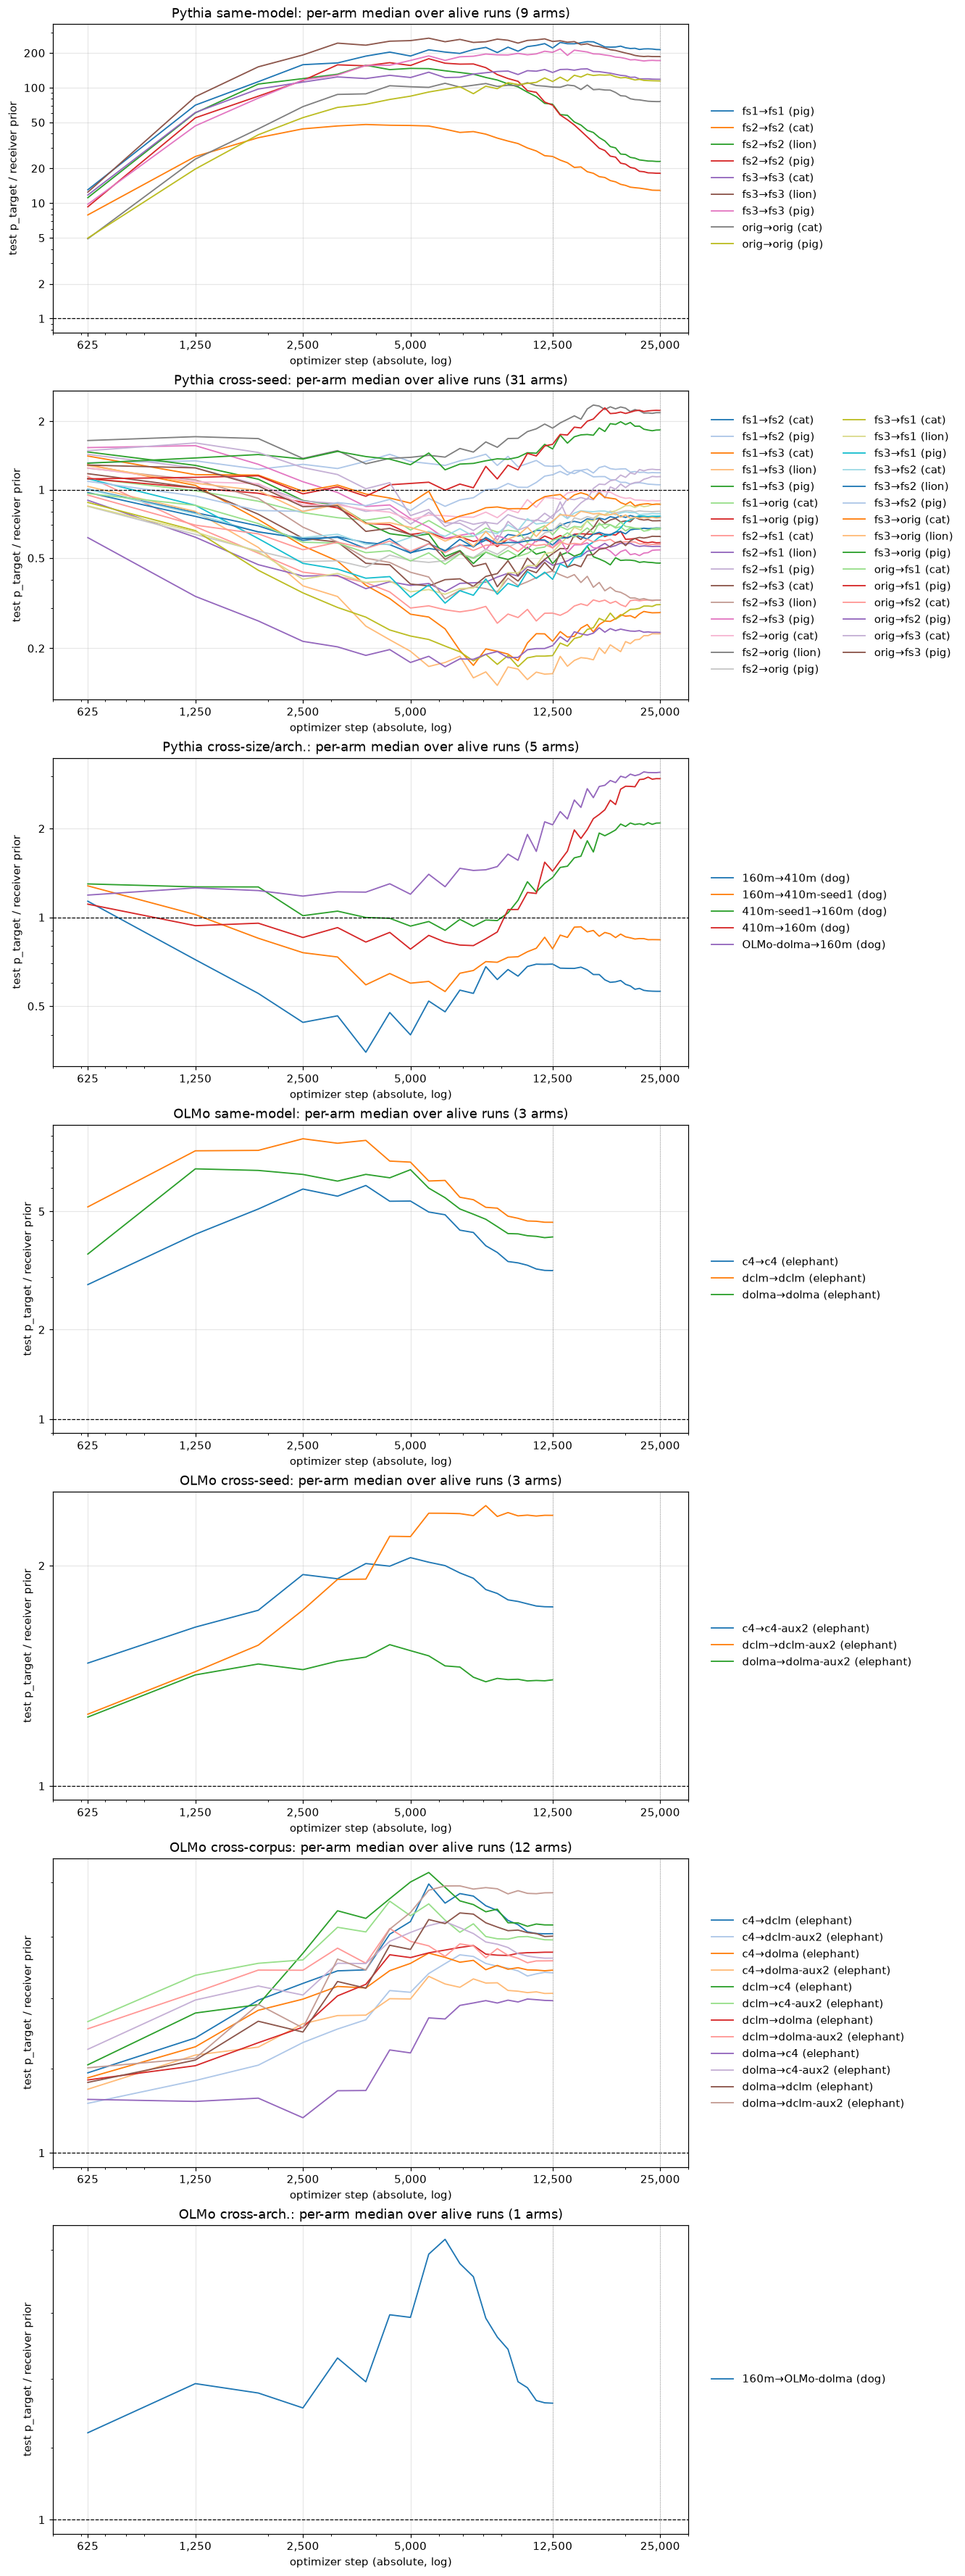

In [3]:
# Per-arm curves (per-model view first): one panel per condition line, one line per arm (median over its
# alive runs, ×prior), dashed = receiver prior (×1), dotted verticals = run ends 12,500 / 25,000.
CURVES = tc.arm_curves(DATA)
fig = tc.plot_arm_curves(CURVES); FIG_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIG_DIR / "transfer_trajectory_conditions_arms.png", dpi=130, bbox_inches="tight")

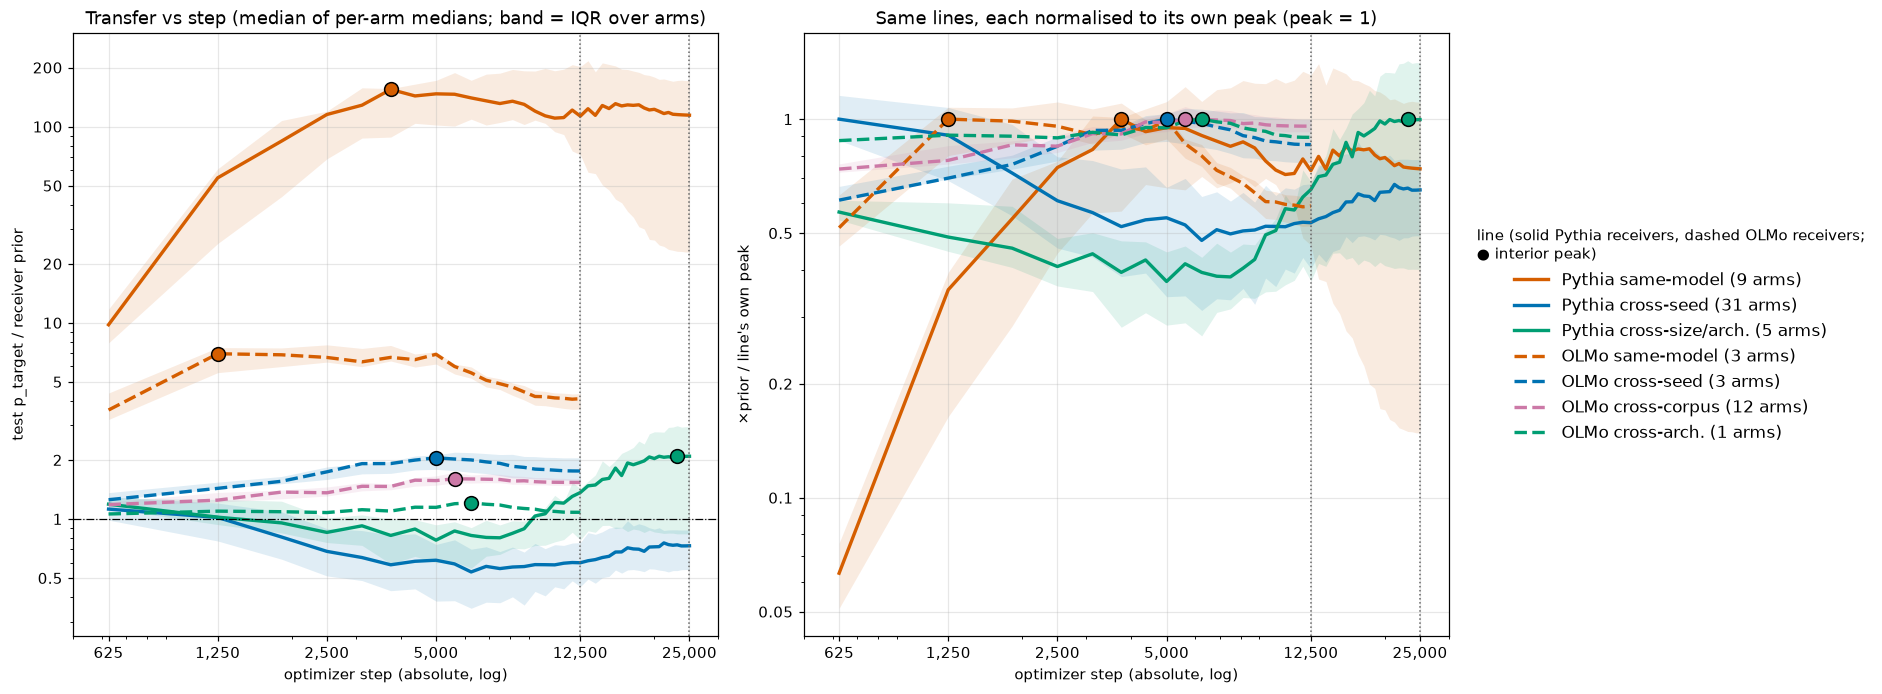

In [4]:
# Headline: every condition line on one axes; left = ×prior, right = each line normalised to its own peak.
POOLED = tc.pooled_curves(CURVES)
fig = tc.plot_pooled(POOLED)
fig.savefig(FIG_DIR / "transfer_trajectory_conditions_pooled.png", dpi=150, bbox_inches="tight")

In [5]:
# Summary (×prior = test p_target / receiver prior). Arm rows: the arm's curve (median over alive runs);
# "peak step" = argmax of that curve; per-run peak = max over each run's saved steps; endpoint = declared final
# step. ALL rows: the pooled curve (median of per-arm medians); endpoint ×prior = median over arms; per-run
# columns pool all alive runs of the line. Early-peak cut-off: step 5,000 (Pythia receivers, 25,000-step runs),
# step 2,500 (OLMo receivers, 12,500-step runs).
SUMMARY = tc.summary_table(DATA)
FMT = {c: "{:.2f}" for c in SUMMARY.columns if c.startswith("×prior") or c == "peak / end"}
display(SUMMARY.set_index("arm / condition").style.format({**FMT, "frac. runs peak before cut-off": "{:.0%}"}, na_rep="—"))

,condition,arms,alive runs,peak step (agg. curve argmax),per-run peak step: median [IQR],"×prior @ step 2,500",×prior @ peak,endpoint step,×prior @ endpoint,peak / end,frac. runs peak before cut-off
arm / condition,,,,,,,,,,,
orig→orig (cat),same-model,1,455,"10,625","10,000 [6,250–14,375]",68.49,110.47,"25,000",75.76,1.46,15%
fs2→fs2 (cat),same-model,1,560,"3,750","4,375 [3,750–6,875]",43.99,47.96,"25,000",12.90,3.72,51%
fs3→fs3 (cat),same-model,1,501,"15,625","10,625 [5,625–15,625]",111.78,145.60,"25,000",118.23,1.23,21%
fs2→fs2 (lion),same-model,1,560,"3,750","5,000 [3,750–6,875]",119.81,156.29,"25,000",22.95,6.81,42%
fs3→fs3 (lion),same-model,1,537,"5,625","8,125 [5,000–13,125]",192.00,268.36,"25,000",185.88,1.44,22%
orig→orig (pig),same-model,1,479,"15,625","13,125 [8,125–17,500]",55.00,130.91,"25,000",114.37,1.14,6%
fs1→fs1 (pig),same-model,1,489,"15,625","11,875 [7,500–16,875]",158.15,250.50,"25,000",213.68,1.17,12%
fs2→fs2 (pig),same-model,1,560,"5,625","5,625 [4,375–7,500]",115.27,178.16,"25,000",18.15,9.82,31%
fs3→fs3 (pig),same-model,1,527,"13,125","10,625 [6,875–15,625]",116.67,216.74,"25,000",171.74,1.26,15%


## Per-checkpoint arms of the four 160m factorials and their base-numbers controls

**Arms.** ftseed 1, fp32 students on the ep20 schedule (25,000 steps), on the 10 stride-3 core30
cells, 10 teachers each (the sender animal's `{animal}_top10_kband_configs.json` tags); arms are
keyed by (animal, sender, receiver). Four factorials of Pythia-160m bases:
cross-seed = every ordered pair of orig/fs1–3 (diagonals included) for dog, cat, lion and pig;
cross-data-order = every ordered pair of orig/ds1–3 (dog); re-pretrain = pr1234 ⇄ orig, prv1 ⇄ orig, every
ordered pair of prv1/wc1/wc2 (dog), plus the dog same-model diagonals ds1–3, wc1–2, prv1 and
pr1234 (`pythia-160m-pilerepro-seed1234`, 10 teachers × 30 cells; pr1234 ⇄ orig also 30 cells).
Each run is read at every step it saved: 625, 1,250, 1,875, 2,500, 3,125, 3,750, 6,250, 12,500
and 25,000 at least, and every 625 steps from 625 to 25,000 where the run's per-checkpoint
readout covers them (cadence column). A run's saved steps are read from both directories of the
same (teacher, cell, ftseed 1) run; where both hold a step they agree (loader notes give the
largest difference). Each arm has a **control** arm trained on base-model numbers with no teacher:
same-base numbers for the same-model arms and the SENDER base's numbers for the cross arms; one
set of control runs serves every animal (each run is read for the arm's animal). Arms, teachers,
cells and control lineages come from the campaign registries and the teacher registries (listed
in the module), not from directory globs. The aggregation rule matches the rest of the notebook;
an arm needs a median of ≥ 8 saved steps. These lines are never pooled with the core-set arms above.

In [6]:
STOP = tc.with_ep20_endpoints(tc.load_arms(tc.earlystop_arms(REPO), OUTPUT_ROOT))
print(f"{len(STOP.arms)} per-checkpoint arms, {len(STOP.runs):,} designed runs; loader notes:", STOP.notes or "none")
STOP_INV = tc.inventory_table(STOP)
display(STOP_INV.drop(columns=["family", "animal"]).set_index(["group", "arm"]).style.format({"receiver prior": "{:.4f}"}))

186 per-checkpoint arms, 10,890 designed runs; loader notes: ['orig→ds1 (dog) · per-checkpoint: the two leaves of a run agree on their shared saved steps within max |Δ p_target| = 0 (6 runs)', 'orig→orig (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)', 'fs1→fs1 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)', 'fs2→fs2 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)', 'fs3→fs3 (dog) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)', 'fs1→fs1 (cat) · per-checkpoint · control: 6 control endpoints used unprobed (no Pile-probe label; a control endpoint is dropped only when labelled dead)', 'orig→orig (lion) · per-c

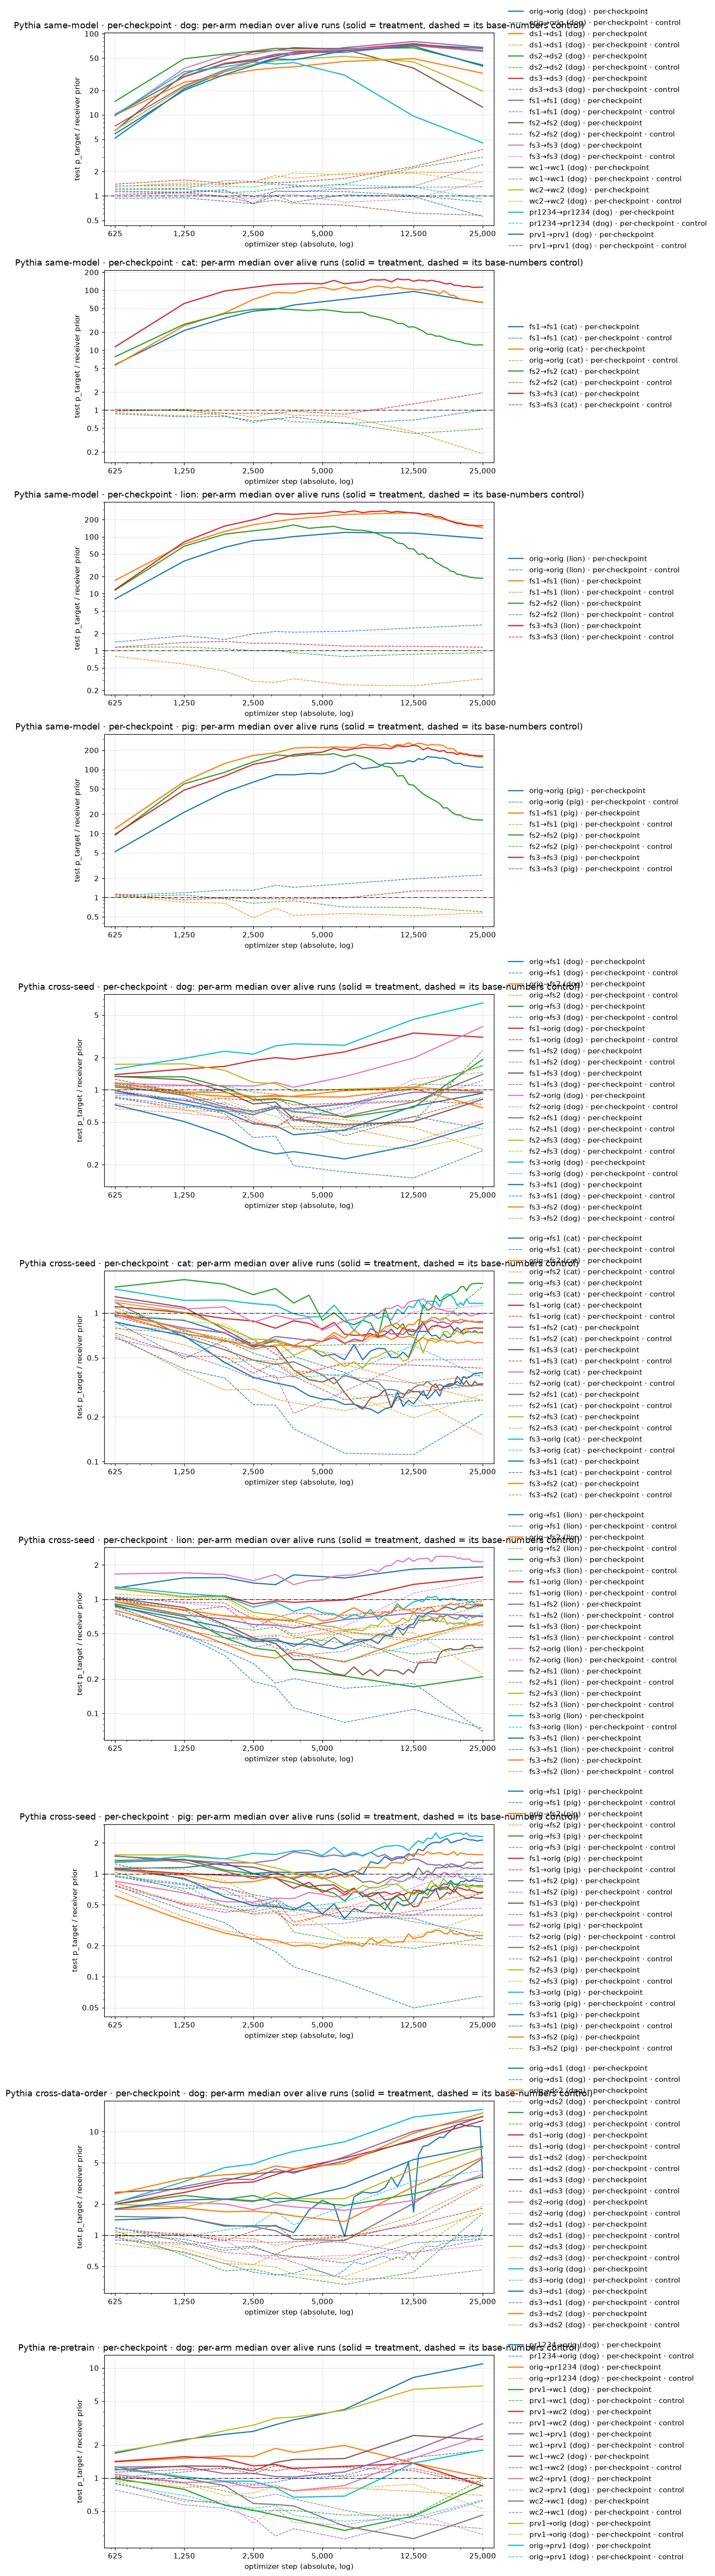

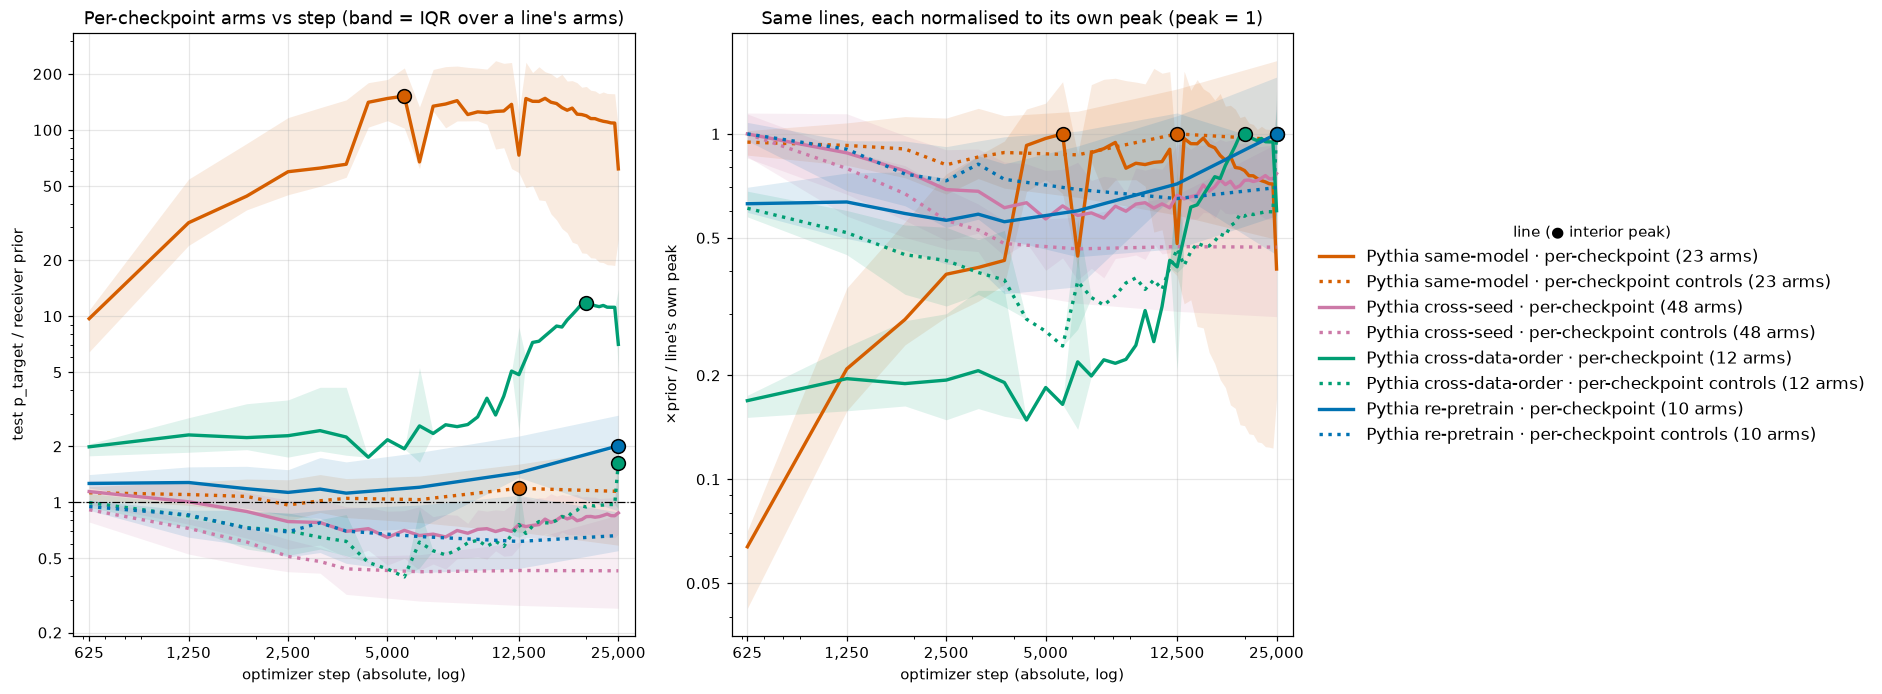

In [7]:
# Per-arm (solid = treatment, dashed same colour = its control) and pooled per-checkpoint figures.
STOP_CURVES = tc.arm_curves(STOP); STOP_POOLED = tc.pooled_curves(STOP_CURVES)
fig = tc.plot_stop_arm_curves(STOP_CURVES, STOP.arms)
fig.savefig(FIG_DIR / "transfer_trajectory_conditions_stop_arms.png", dpi=130, bbox_inches="tight")
fig = tc.plot_stop_pooled(STOP_POOLED, STOP_CURVES)
fig.savefig(FIG_DIR / "transfer_trajectory_conditions_stop_pooled.png", dpi=150, bbox_inches="tight")

In [8]:
# Per-checkpoint summary, same columns as above, plus the DERIVED column "×prior @ peak / control @ same step": the treatment
# curve's peak over its control's curve at that step (ALL rows: pooled treatment line over pooled control line).
STOP_SUMMARY = tc.summary_table(STOP, tc.STOP_GROUPS)
FMT = {c: "{:.2f}" for c in STOP_SUMMARY.columns if c.startswith("×prior") or c == "peak / end"}
display(STOP_SUMMARY.set_index("arm / condition").style.format({**FMT, "frac. runs peak before cut-off": "{:.0%}"}, na_rep="—"))

,condition,arms,alive runs,peak step (agg. curve argmax),per-run peak step: median [IQR],"×prior @ step 2,500",×prior @ peak,endpoint step,×prior @ endpoint,peak / end,frac. runs peak before cut-off,×prior @ peak / control @ same step (derived)
arm / condition,,,,,,,,,,,,
orig→orig (dog) · per-checkpoint,same-model · per-checkpoint,1,89,"12,500","12,500 [12,500–25,000]",41.54,73.23,"25,000",65.88,1.11,12%,72.36
ds1→ds1 (dog) · per-checkpoint,same-model · per-checkpoint,1,96,"12,500","12,500 [6,250–12,500]",35.70,49.31,"25,000",32.52,1.52,10%,25.22
ds2→ds2 (dog) · per-checkpoint,same-model · per-checkpoint,1,95,"12,500","12,500 [3,750–12,500]",60.91,66.92,"25,000",41.15,1.63,34%,30.21
ds3→ds3 (dog) · per-checkpoint,same-model · per-checkpoint,1,88,"12,500","12,500 [6,250–12,500]",46.54,75.27,"25,000",61.79,1.22,17%,32.74
fs1→fs1 (dog) · per-checkpoint,same-model · per-checkpoint,1,91,"12,500","12,500 [6,250–25,000]",44.80,80.01,"25,000",67.88,1.18,11%,61.04
fs2→fs2 (dog) · per-checkpoint,same-model · per-checkpoint,1,100,"3,750","3,750 [3,125–6,250]",59.68,67.29,"25,000",12.43,5.41,56%,82.70
fs3→fs3 (dog) · per-checkpoint,same-model · per-checkpoint,1,93,"12,500","12,500 [3,750–12,500]",55.70,71.13,"25,000",60.33,1.18,28%,77.53
wc1→wc1 (dog) · per-checkpoint,same-model · per-checkpoint,1,84,"12,500","12,500 [6,250–25,000]",48.34,72.35,"25,000",61.75,1.17,18%,56.65
wc2→wc2 (dog) · per-checkpoint,same-model · per-checkpoint,1,100,"6,250","6,250 [6,250–12,500]",41.64,52.68,"25,000",19.58,2.69,24%,28.99


### Cross-direction asymmetry: pr1234 → orig vs orig → pr1234

**Rows.** A = pr1234 → orig, B = orig → pr1234 (dog, per-checkpoint arms). Columns are the saved
steps both arms share (absolute optimizer steps). "median ×prior" = median over every alive run
at that step; "control" = the arm's base-numbers control (alive runs only); "(T−C)/prior" =
×prior minus the control's ×prior. **Pairing:** by cell name; per arm and cell the value is the
median over that cell's alive teachers; only cells present in both arms enter. "cells A > B"
counts those cells; "median paired log2(A/B)" is their median log-ratio. Sign test and Wilcoxon
signed-rank test are two-sided, with zero paired differences dropped (scipy). "frac. A runs > B
median" = share of A's alive runs above B's run-level median at that step (and vice versa).

In [9]:
A_ARM, B_ARM = "pr1234→orig (dog) · per-checkpoint", "orig→pr1234 (dog) · per-checkpoint"
ASYM = tc.asymmetry_table(STOP, A_ARM, B_ARM)
COUNT_ROWS = {"alive runs A / B", "cells A > B (×prior)", "cells A > B (control-subtracted)"}
P_ROWS = {r for r in ASYM.index if " p (" in r}
fmt = lambda r, v: v if r in COUNT_ROWS else (f"{v:.2e}" if r in P_ROWS else f"{v:.3g}")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 20)
print(ASYM.apply(lambda col: [fmt(r, v) for r, v in col.items()]).to_string())
print("Verdict:", tc.asymmetry_verdict(ASYM))

                                     625       1250      1875      2500      3125      3750      6250      12500     25000
alive runs A / B                   283/300   283/300   283/300   283/300   283/300   283/300   283/300   283/300   279/300
median ×prior A                       1.68      2.24      2.49      2.65      3.05      3.37       4.2       8.2      10.9
median ×prior B                        1.4      1.51      1.59      1.57      1.86      1.71      1.98      1.37      1.01
control median ×prior A               1.03      0.91     0.926     0.876      0.92     0.986      1.06      1.54      1.77
control median ×prior B              0.964     0.822     0.845     0.859     0.861     0.767     0.816     0.755     0.697
A / control                           1.63      2.46      2.69      3.03      3.31      3.42      3.98      5.33      6.15
B / control                           1.45      1.84      1.88      1.82      2.16      2.23      2.42      1.81      1.45
(T−C)/prior A   

## Conclusion

Read from the summary table's pooled rows (×prior = test p_target / receiver prior):

* **OLMo-1B: same-model peaks early and decays; cross-model barely does.** OLMo same-model peaks
  at step 1,250 (6.95× prior) and ends at 4.10× by step 12,500 (peak/end 1.70; per-arm
  1.70–1.93). OLMo cross-seed peaks later, at step 5,000 (2.05×), and ends at 1.76× (peak/end 1.17).
  OLMo cross-corpus (12 arms) peaks at step 5,625 (1.60×) and stays flat to the end (1.54×, peak/end 1.04).
* **Pythia-160m same-model is large but not uniformly early.** The pooled line peaks at step 3,750
  (155×) and ends at 114× (peak/end 1.35). Only 24% of alive runs peak before step 5,000. The fs2
  diagonals (cat, lion, pig) peak at steps 3,750–5,625 and decay 3.7–9.8×. The orig / fs1 / fs3
  diagonals peak at steps 10,625–15,625 and lose ≤ 1.46×.
* **Pythia cross-seed shows no transfer to decay from.** The pooled line's maximum is its first
  checkpoint (1.12× at step 625, so no interior peak). It sits *below* the prior from step 2,500 on
  (0.68× at 2,500; 0.73× at 25,000).
* **Pythia-receiver cross-size / cross-architecture rises late and does not decay.** The 5 arms
  (all 25,000 steps) sit below the prior at step 2,500 (0.85×). They peak at step 23,125 (2.09×) and
  end at 2.09× (peak/end 1.00). OLMo→160m alone peaks at step 22,500 (3.11×, end 3.10×).
* **OLMo-receiver cross-architecture (160m → OLMo-dolma, dog, 1 arm, 12,500 steps) is near the
  prior throughout.** It peaks at step 6,250 (1.21×) and ends at 1.08× (peak/end 1.12).

So "early peak then decay" holds cleanly only for OLMo same-model and the Pythia fs2 diagonals.
The other Pythia diagonals peak mid-run and keep most of their transfer. The cross-model lines
are flat (OLMo) or late-rising (Pythia cross-size/arch.) rather than decaying.

* **The pr1234 ↔ orig cross pair is asymmetric from the first checkpoint.** pr1234 → orig exceeds
  orig → pr1234 at every saved step (step 625: 1.68× vs 1.40×, 30/30 cells, Wilcoxon p = 1.9e-9;
  step 12,500: 8.2× vs 1.37×, control-subtracted 6.67 vs 0.61, 28/30 cells), and the gap widens
  by the ep20 endpoint (10.9× vs 1.01× at step 25,000).